# Smart Outcome Predictor


## Project Objective

The objective of this project is to build and compare ensemble-based machine learning models , where single models were giving unstable predictions. The project covers two supervised learning tasks on a dataset of 5,200 students:

- **Classification:** Predict whether a student will successfully complete an online course (`completion_status`).
- **Regression:** Predict the student's final performance score (`final_score`, 0 to 100).



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import BaggingClassifier, BaggingRegressor
from sklearn.ensemble import AdaBoostClassifier, AdaBoostRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.ensemble import VotingClassifier, StackingClassifier, StackingRegressor
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error, mean_squared_error, r2_score, roc_auc_score, roc_curve


# Part A: Conceptual Foundation

### 1. What are Ensemble Learning Methods and why are they effective?
Ensemble learning means combining many models to make one final prediction. One model can make mistakes, but different models make different mistakes, so when we combine them the errors cancel out. This gives better accuracy and more stable results.

### 2. Difference between Bagging, Boosting, and Voting
- **Bagging:** Same model is trained many times in parallel on random samples of the data. Final answer is the average (regression) or majority vote (classification). It reduces variance.
- **Boosting:** Models are trained one after another. Each new model focuses on the mistakes of the previous one. It reduces bias.
- **Voting:** Different types of models (e.g., Logistic Regression, KNN, Decision Tree) are trained on the same data and their predictions are combined.

### 3. Bias-Variance Trade-off
- **Bias** = error from a model that is too simple (underfitting).
- **Variance** = error from a model that is too sensitive to training data (overfitting).
- Reducing one usually increases the other, so we need a balance.
- Bagging reduces variance by averaging many models. Boosting reduces bias by fixing errors step by step.

### 4. Voting Classifier and Stacking Ensemble
- **Voting Classifier:** Several different classifiers predict separately.
  - Hard voting: the class with the most votes wins.
  - Soft voting: the predicted probabilities are averaged, and the highest wins.
- **Stacking Ensemble:** Predictions of the base models are given as input to another model called a meta-learner (e.g., Logistic Regression), which learns the best way to combine them.

### 5. AdaBoost vs XGBoost
- **AdaBoost:** Uses simple weak learners (small trees). It increases the weight of wrongly predicted samples so the next learner focuses on them. Simple, but sensitive to noise and outliers.
- **XGBoost:** Gradient boosting where each new tree corrects the errors (loss) of the previous trees. It has regularization, handles missing values, and is faster and usually more accurate, but needs more tuning.

# Part B: Dataset Understanding & Preparation


In [2]:
df = pd.read_excel("Dataset/Smart_Outcome_Predictor_Dataset_5200.xlsx")
df.head()

,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [3]:
df.shape

(5200, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   student_id             5200 non-null   int64         
 1   age                    5200 non-null   int64         
 2   country_region         5200 non-null   object        
 3   device_type            5200 non-null   object        
 4   education_background   5200 non-null   object        
 5   course_level           5200 non-null   object        
 6   course_category        5200 non-null   object        
 7   course_start_date      5200 non-null   datetime64[ns]
 8   week_of_year           5200 non-null   int64         
 9   sessions               5200 non-null   int64         
 10  time_spent_hours       5088 non-null   float64       
 11  videos_watched         5200 non-null   int64         
 12  quiz_attempts          5200 non-null   int64         
 13  ass

In [5]:
df.isna().sum()

,0
student_id,0
age,0
country_region,0
device_type,0
education_background,0
course_level,0
course_category,0
course_start_date,0
week_of_year,0
sessions,0


In [6]:
df = df.drop(columns=['student_id','course_start_date'])

In [7]:
df["course_level"] = df["course_level"].map({"Beginner": 0, "Intermediate": 1, "Advanced": 2})

In [8]:
df = pd.get_dummies(
    df,
    columns=["country_region", "device_type", "education_background", "course_category"],
    drop_first=True,
    dtype=int
)

In [9]:
df.columns

Index(['age', 'course_level', 'week_of_year', 'sessions', 'time_spent_hours',
       'videos_watched', 'quiz_attempts', 'assignments_submitted',
       'forum_posts', 'avg_quiz_score', 'attendance_rate', 'completion_status',
       'final_score', 'country_region_Americas', 'country_region_Asia',
       'country_region_Europe', 'country_region_Oceania', 'device_type_Mobile',
       'device_type_Tablet', 'education_background_HighSchool',
       'education_background_Undergrad', 'education_background_WorkingPro',
       'course_category_Data', 'course_category_Design',
       'course_category_Marketing', 'course_category_Programming'],
      dtype='object')

In [10]:
X = df.drop(columns=["completion_status", "final_score"])
y_clf = df["completion_status"]   # classification target
y_reg = df["final_score"]         # regression target
print("Features:", list(X.columns))

Features: ['age', 'course_level', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate', 'country_region_Americas', 'country_region_Asia', 'country_region_Europe', 'country_region_Oceania', 'device_type_Mobile', 'device_type_Tablet', 'education_background_HighSchool', 'education_background_Undergrad', 'education_background_WorkingPro', 'course_category_Data', 'course_category_Design', 'course_category_Marketing', 'course_category_Programming']


In [11]:
X_train, X_test, y_clf_train, y_clf_test, y_reg_train, y_reg_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, random_state=42, stratify=y_clf
)
print(X_train.shape, X_test.shape)

(4160, 24) (1040, 24)


In [12]:
for col in ["time_spent_hours", "avg_quiz_score", "attendance_rate"]:
    imputer = SimpleImputer(strategy="median")
    X_train[col] = imputer.fit_transform(X_train[[col]])
    X_test[col] = imputer.transform(X_test[[col]])

print("Missing after imputation:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing after imputation: 0 0


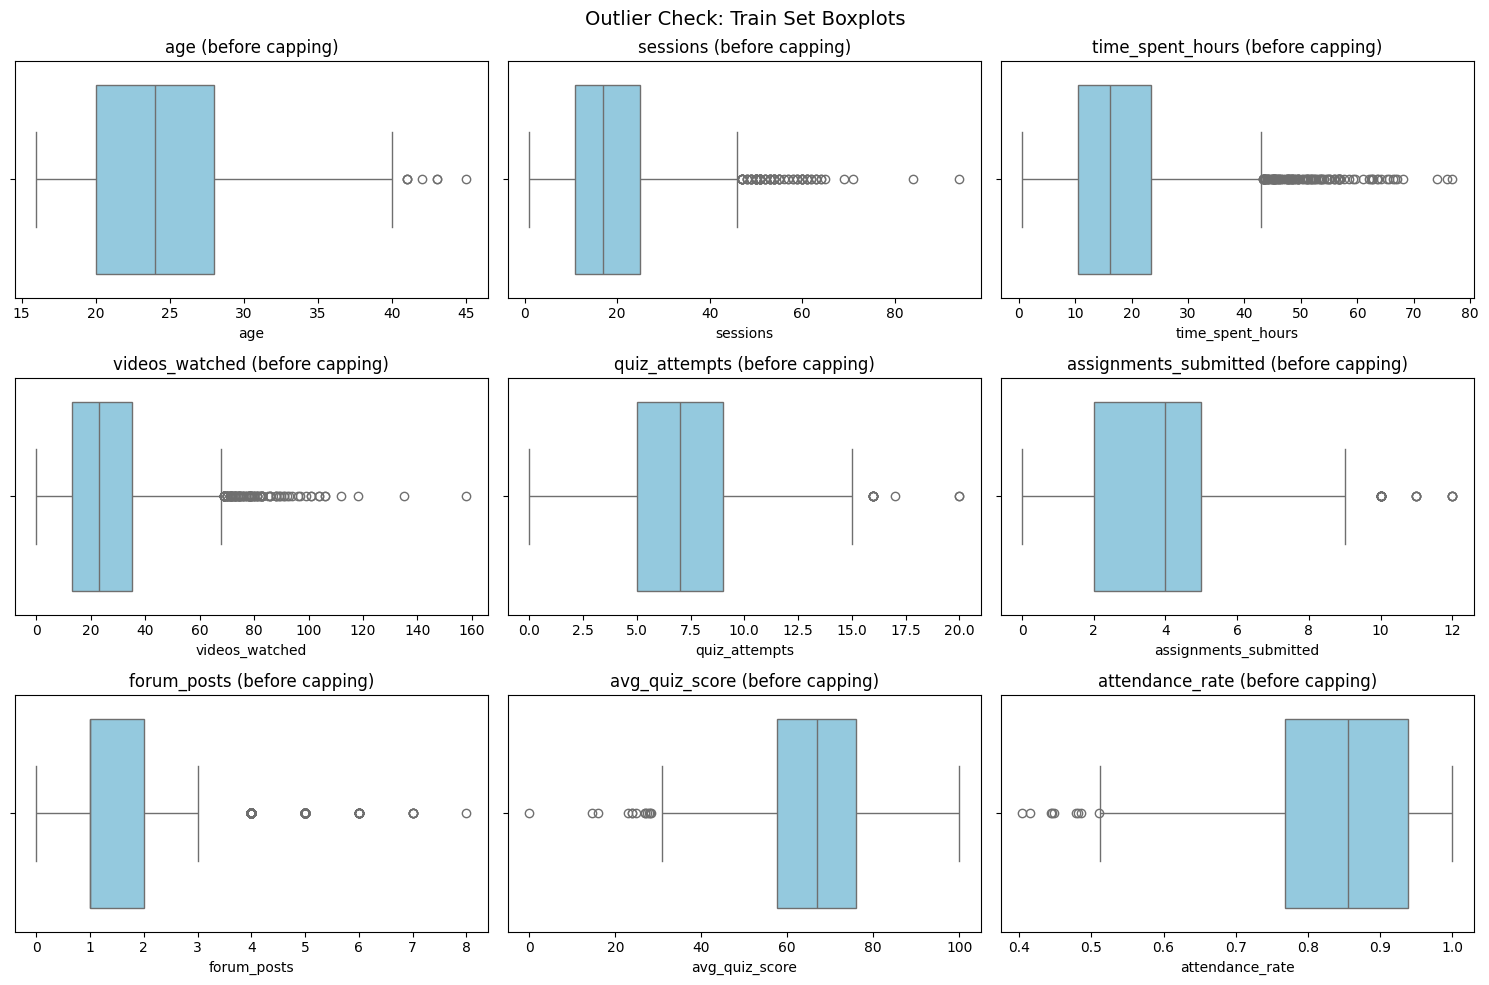

In [13]:
plot_cols = ["age", "sessions", "time_spent_hours", "videos_watched", "quiz_attempts",
             "assignments_submitted", "forum_posts", "avg_quiz_score", "attendance_rate"]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.ravel()
for i, col in enumerate(plot_cols):
    sns.boxplot(x=X_train[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col + " (before capping)")
plt.suptitle("Outlier Check: Train Set Boxplots", fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
for col in ["sessions", "time_spent_hours", "videos_watched"]:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    print(col, "| train values capped:", ((X_train[col] < lower) | (X_train[col] > upper)).sum())
    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

sessions | train values capped: 84
time_spent_hours | train values capped: 122
videos_watched | train values capped: 112


# Part C: Bagging (Bootstrap Aggregating)


In [15]:
clf_results = []

bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    bootstrap=True,
    n_jobs=-1,
    random_state=42
)

bag_clf.fit(X_train, y_clf_train)
y_clf_pred = bag_clf.predict(X_test)
y_clf_prob = bag_clf.predict_proba(X_test)[:, 1]

clf_results.append({
    "Model": "Bagging Classifier",
    "Accuracy": accuracy_score(y_clf_test, y_clf_pred),
    "Precision": precision_score(y_clf_test, y_clf_pred),
    "Recall": recall_score(y_clf_test, y_clf_pred),
    "F1": f1_score(y_clf_test, y_clf_pred),
    "ROC-AUC": roc_auc_score(y_clf_test, y_clf_prob)
})
print(clf_results[-1])

{'Model': 'Bagging Classifier', 'Accuracy': 0.7009615384615384, 'Precision': 0.6158357771260997, 'Recall': 0.5384615384615384, 'F1': 0.5745554035567716, 'ROC-AUC': np.float64(0.758303747534517)}


In [16]:
reg_results = []

bag_reg = BaggingRegressor(
    estimator=DecisionTreeRegressor(random_state=42),
    n_estimators=100, random_state=42, n_jobs=-1
)
bag_reg.fit(X_train, y_reg_train)

y_pred = bag_reg.predict(X_test)

reg_results.append({
    "Model": "Bagging Regressor",
    "MAE": mean_absolute_error(y_reg_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_pred)),
    "R2": r2_score(y_reg_test, y_pred)
})
print(reg_results[-1])

{'Model': 'Bagging Regressor', 'MAE': 8.31541153846154, 'RMSE': np.float64(10.34877495890214), 'R2': 0.4117013092177666}


In [17]:
# Single Decision Tree Classifier
dt_clf = DecisionTreeClassifier(random_state=42)
dt_clf.fit(X_train, y_clf_train)
y_pred = dt_clf.predict(X_test)
y_prob = dt_clf.predict_proba(X_test)[:, 1]

clf_results.append({
    "Model": "Single Decision Tree (Clf)",
    "Accuracy": accuracy_score(y_clf_test, y_pred),
    "Precision": precision_score(y_clf_test, y_pred),
    "Recall": recall_score(y_clf_test, y_pred),
    "F1": f1_score(y_clf_test, y_pred),
    "ROC-AUC": roc_auc_score(y_clf_test, y_prob)
})

In [18]:
# Single Decision Tree Regressor
dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(X_train, y_reg_train)
y_pred = dt_reg.predict(X_test)

reg_results.append({
    "Model": "Single Decision Tree (Reg)",
    "MAE": mean_absolute_error(y_reg_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_pred)),
    "R2": r2_score(y_reg_test, y_pred)
})

In [19]:
print("Classification: Bagging vs Single Tree")
print(pd.DataFrame(clf_results).round(2))
print("\nRegression: Bagging vs Single Tree")
print(pd.DataFrame(reg_results).round(2))

Classification: Bagging vs Single Tree
                        Model  Accuracy  Precision  Recall    F1  ROC-AUC
0          Bagging Classifier      0.70       0.62    0.54  0.57     0.76
1  Single Decision Tree (Clf)      0.64       0.51    0.54  0.53     0.62

Regression: Bagging vs Single Tree
                        Model    MAE   RMSE    R2
0           Bagging Regressor   8.32  10.35  0.41
1  Single Decision Tree (Reg)  11.22  14.19 -0.11


# Part D: Boosting Algorithms



## AdaBoost

In [20]:
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),   # stump
    n_estimators=100, learning_rate=0.5, random_state=42
)
ada_clf.fit(X_train, y_clf_train)

y_pred = ada_clf.predict(X_test)
y_prob = ada_clf.predict_proba(X_test)[:, 1]

clf_results.append({
    "Model": "AdaBoost Classifier",
    "Accuracy": accuracy_score(y_clf_test, y_pred),
    "Precision": precision_score(y_clf_test, y_pred),
    "Recall": recall_score(y_clf_test, y_pred),
    "F1": f1_score(y_clf_test, y_pred),
    "ROC-AUC": roc_auc_score(y_clf_test, y_prob)
})
print(clf_results[-1])

{'Model': 'AdaBoost Classifier', 'Accuracy': 0.7365384615384616, 'Precision': 0.6883116883116883, 'Recall': 0.5435897435897435, 'F1': 0.6074498567335244, 'ROC-AUC': np.float64(0.7849388560157791)}


In [21]:
ada_reg = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=3),
    n_estimators=100, learning_rate=0.5, random_state=42
)
ada_reg.fit(X_train, y_reg_train)

y_pred = ada_reg.predict(X_test)

reg_results.append({
    "Model": "AdaBoost Regressor",
    "MAE": mean_absolute_error(y_reg_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_pred)),
    "R2": r2_score(y_reg_test, y_pred)
})
print(reg_results[-1])

{'Model': 'AdaBoost Regressor', 'MAE': 8.60813434647855, 'RMSE': np.float64(10.580593245096058), 'R2': 0.38504967739326657}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


After 1 learners -> Accuracy: 0.6625 | R2: 0.2764
After 10 learners -> Accuracy: 0.7038 | R2: 0.363
After 50 learners -> Accuracy: 0.7356 | R2: 0.3903
After 100 learners -> Accuracy: 0.7365 | R2: 0.385


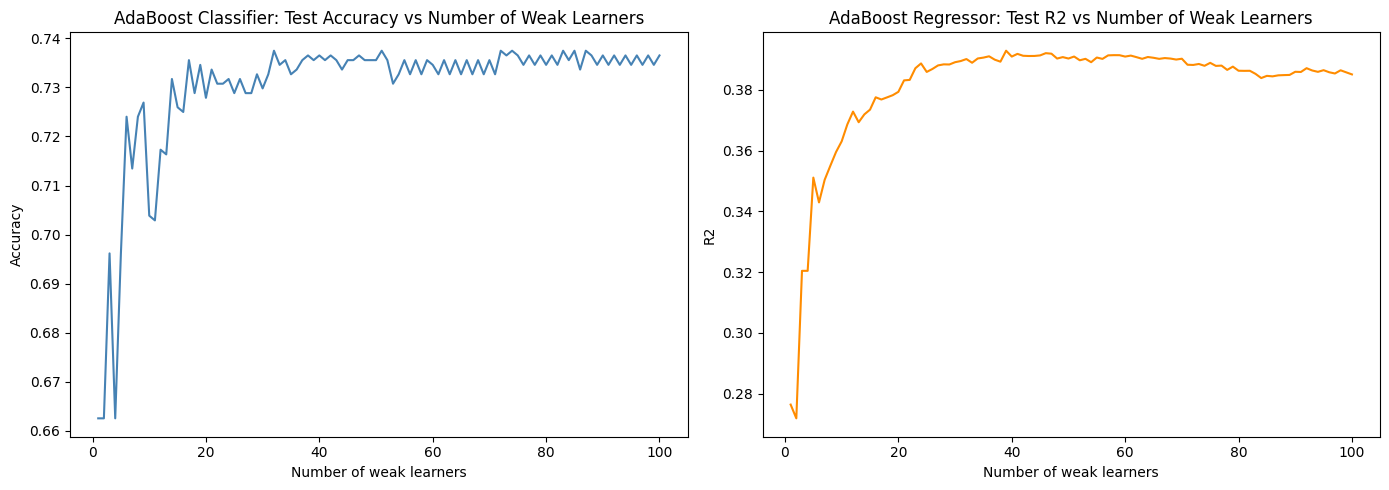

In [22]:
# Test performance after adding each weak learner one by one
stage_acc = [accuracy_score(y_clf_test, p) for p in ada_clf.staged_predict(X_test)]
stage_r2 = [r2_score(y_reg_test, p) for p in ada_reg.staged_predict(X_test)]

for n in [1, 10, 50, 100]:
    print("After", n, "learners -> Accuracy:", round(stage_acc[n - 1], 4), "| R2:", round(stage_r2[n - 1], 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(stage_acc) + 1), stage_acc, color="steelblue")
axes[0].set_title("AdaBoost Classifier: Test Accuracy vs Number of Weak Learners")
axes[0].set_xlabel("Number of weak learners")
axes[0].set_ylabel("Accuracy")

axes[1].plot(range(1, len(stage_r2) + 1), stage_r2, color="darkorange")
axes[1].set_title("AdaBoost Regressor: Test R2 vs Number of Weak Learners")
axes[1].set_xlabel("Number of weak learners")
axes[1].set_ylabel("R2")

plt.tight_layout()
plt.show()

## XGBoost

In [23]:
xgb_clf = XGBClassifier(
     n_estimators=200, learning_rate=0.05, max_depth=3,
     subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric="logloss"
)

xgb_clf.fit(X_train, y_clf_train)

y_pred = xgb_clf.predict(X_test)
y_prob = xgb_clf.predict_proba(X_test)[:, 1]


clf_results.append({
    "Model": "XGBoost Classifier",
    "Accuracy": accuracy_score(y_clf_test, y_pred),
    "Precision": precision_score(y_clf_test, y_pred),
    "Recall": recall_score(y_clf_test, y_pred),
    "F1": f1_score(y_clf_test, y_pred),
    "ROC-AUC": roc_auc_score(y_clf_test, y_prob)
})
print(clf_results[-1])

{'Model': 'XGBoost Classifier', 'Accuracy': 0.7326923076923076, 'Precision': 0.6627906976744186, 'Recall': 0.5846153846153846, 'F1': 0.6212534059945504, 'ROC-AUC': np.float64(0.7876370808678501)}


In [24]:
xgb_reg = XGBRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=3,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_reg.fit(X_train, y_reg_train)

y_pred = xgb_reg.predict(X_test)

reg_results.append({
    "Model": "XGBoost Regressor",
    "MAE": mean_absolute_error(y_reg_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_pred)),
    "R2": r2_score(y_reg_test, y_pred)
})
print(reg_results[-1])

{'Model': 'XGBoost Regressor', 'MAE': 8.128323996617244, 'RMSE': np.float64(10.130948801671185), 'R2': 0.43620627611638796}


In [25]:
print("Classification results so far")
print(pd.DataFrame(clf_results).round(2))
print("\nRegression results so far")
print(pd.DataFrame(reg_results).round(2))

# Robustness: 5-fold cross-validation on the training set (mean and spread)
cv_rows = []
for name, model, y, metric in [
    ("AdaBoost Classifier", ada_clf, y_clf_train, "roc_auc"),
    ("XGBoost Classifier", xgb_clf, y_clf_train, "roc_auc"),
    ("AdaBoost Regressor", ada_reg, y_reg_train, "r2"),
    ("XGBoost Regressor", xgb_reg, y_reg_train, "r2"),
]:
    scores = cross_val_score(model, X_train, y, cv=5, scoring=metric)
    cv_rows.append({"Model": name, "CV Metric": metric,
                    "CV Mean": scores.mean(), "CV Std": scores.std()})

print("\n5-fold CV (robustness)")
print(pd.DataFrame(cv_rows).round(4))

Classification results so far
                        Model  Accuracy  Precision  Recall    F1  ROC-AUC
0          Bagging Classifier      0.70       0.62    0.54  0.57     0.76
1  Single Decision Tree (Clf)      0.64       0.51    0.54  0.53     0.62
2         AdaBoost Classifier      0.74       0.69    0.54  0.61     0.78
3          XGBoost Classifier      0.73       0.66    0.58  0.62     0.79

Regression results so far
                        Model    MAE   RMSE    R2
0           Bagging Regressor   8.32  10.35  0.41
1  Single Decision Tree (Reg)  11.22  14.19 -0.11
2          AdaBoost Regressor   8.61  10.58  0.39
3           XGBoost Regressor   8.13  10.13  0.44

5-fold CV (robustness)
                 Model CV Metric  CV Mean  CV Std
0  AdaBoost Classifier   roc_auc   0.7702  0.0083
1   XGBoost Classifier   roc_auc   0.7739  0.0088
2   AdaBoost Regressor        r2   0.4248  0.0085
3    XGBoost Regressor        r2   0.4895  0.0056


# Part E: Voting & Stacking Ensembles


## Voting

In [26]:
base_clf_results = []

lr_model = Pipeline([("scaler", StandardScaler()), ("lr", LogisticRegression(max_iter=1000))])
knn_model = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=15))])
svm_model = Pipeline([("scaler", StandardScaler()), ("svm", SVC(probability=True, random_state=42))])
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)

base_clfs = [("lr", lr_model), ("knn", knn_model), ("svm", svm_model), ("dt", dt_model)]

for name, model in base_clfs:
    model.fit(X_train, y_clf_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    base_clf_results.append({
        "Model": name.upper(),
        "Accuracy": accuracy_score(y_clf_test, y_pred),
        "Precision": precision_score(y_clf_test, y_pred),
        "Recall": recall_score(y_clf_test, y_pred),
        "F1": f1_score(y_clf_test, y_pred),
        "ROC-AUC": roc_auc_score(y_clf_test, y_prob)
    })

print(pd.DataFrame(base_clf_results).round(2))

  Model  Accuracy  Precision  Recall    F1  ROC-AUC
0    LR      0.75       0.69    0.59  0.63     0.79
1   KNN      0.66       0.60    0.33  0.42     0.69
2   SVM      0.72       0.65    0.56  0.60     0.76
3    DT      0.70       0.66    0.43  0.52     0.75


In [27]:
# Hard voting
hard_vote = VotingClassifier(estimators=base_clfs, voting="hard")
hard_vote.fit(X_train, y_clf_train)
y_pred = hard_vote.predict(X_test)

clf_results.append({
    "Model": "Voting Classifier (Hard)",
    "Accuracy": accuracy_score(y_clf_test, y_pred),
    "Precision": precision_score(y_clf_test, y_pred),
    "Recall": recall_score(y_clf_test, y_pred),
    "F1": f1_score(y_clf_test, y_pred),
    "ROC-AUC": np.nan
})


In [28]:
# Soft voting
soft_vote = VotingClassifier(estimators=base_clfs, voting="soft")
soft_vote.fit(X_train, y_clf_train)
y_pred = soft_vote.predict(X_test)
y_prob = soft_vote.predict_proba(X_test)[:, 1]

clf_results.append({
    "Model": "Voting Classifier (Soft)",
    "Accuracy": accuracy_score(y_clf_test, y_pred),
    "Precision": precision_score(y_clf_test, y_pred),
    "Recall": recall_score(y_clf_test, y_pred),
    "F1": f1_score(y_clf_test, y_pred),
    "ROC-AUC": roc_auc_score(y_clf_test, y_prob)
})

In [29]:
print(pd.DataFrame(clf_results[-2:]).round(4))

                      Model  Accuracy  Precision  Recall      F1  ROC-AUC
0  Voting Classifier (Hard)    0.7202     0.7054  0.4359  0.5388      NaN
1  Voting Classifier (Soft)    0.7250     0.6781  0.5077  0.5806   0.7816


**Interpretation:** Soft voting is better. Its recall is higher (about 0.51 vs 0.44) and its F1 is higher (about 0.58 vs 0.54). It also gives probabilities, so ROC-AUC (about 0.78) can be computed, while hard voting returns only class labels. Soft voting uses each model's confidence, while hard voting throws it away.

## Stacking Classifier




In [30]:
stack_clf = StackingClassifier(
    estimators=base_clfs,
    final_estimator=LogisticRegression(max_iter=1000),   # meta-learner
    cv=5
)
stack_clf.fit(X_train, y_clf_train)

y_pred = stack_clf.predict(X_test)
y_prob = stack_clf.predict_proba(X_test)[:, 1]

clf_results.append({
    "Model": "Stacking Classifier",
    "Accuracy": accuracy_score(y_clf_test, y_pred),
    "Precision": precision_score(y_clf_test, y_pred),
    "Recall": recall_score(y_clf_test, y_pred),
    "F1": f1_score(y_clf_test, y_pred),
    "ROC-AUC": roc_auc_score(y_clf_test, y_prob)
})
print(clf_results[-1])

{'Model': 'Stacking Classifier', 'Accuracy': 0.7423076923076923, 'Precision': 0.6859756097560976, 'Recall': 0.5769230769230769, 'F1': 0.6267409470752089, 'ROC-AUC': np.float64(0.7940276134122288)}


## Stacking Regressor


In [31]:
base_reg_results = []

ridge_model = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
knn_reg_model = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor(n_neighbors=15))])
svr_model = Pipeline([("scaler", StandardScaler()), ("svr", SVR())])
dt_reg_model = DecisionTreeRegressor(max_depth=5, random_state=42)

base_regs = [("ridge", ridge_model), ("knn", knn_reg_model), ("svr", svr_model), ("dt", dt_reg_model)]

for name, model in base_regs:
    model.fit(X_train, y_reg_train)
    y_pred = model.predict(X_test)
    base_reg_results.append({
        "Model": name.upper(),
        "MAE": mean_absolute_error(y_reg_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_pred)),
        "R2": r2_score(y_reg_test, y_pred)
    })
print(pd.DataFrame(base_reg_results).round(4))

   Model     MAE     RMSE      R2
0  RIDGE  8.0879  10.0614  0.4439
1    KNN  9.2712  11.4242  0.2831
2    SVR  8.2471  10.2050  0.4279
3     DT  8.7746  10.9993  0.3354


In [32]:
stack_reg = StackingRegressor(
    estimators=base_regs,
    final_estimator=Ridge(),    # meta-learner
    cv=5
)
stack_reg.fit(X_train, y_reg_train)
y_pred = stack_reg.predict(X_test)

reg_results.append({
    "Model": "Stacking Regressor",
    "MAE": mean_absolute_error(y_reg_test, y_pred),
    "RMSE": np.sqrt(mean_squared_error(y_reg_test, y_pred)),
    "R2": r2_score(y_reg_test, y_pred)
})
print(reg_results[-1])

{'Model': 'Stacking Regressor', 'MAE': 8.067451424888885, 'RMSE': np.float64(10.047523622655161), 'R2': 0.4454533734451932}


**Interpretation:** The Stacking Regressor (R2 about 0.446, RMSE about 10.05) is only marginally better than its best base model, Ridge (R2 about 0.444). Stacking helps by combining models, but here one base model already captures most of the signal.

# Part F: Model Evaluation & Comparison

## Evaluate Classification Models

In [33]:
clf_df = pd.DataFrame(clf_results).set_index("Model")
clf_df = clf_df.sort_values("ROC-AUC", ascending=False)
clf_df.round(2)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Stacking Classifier,0.74,0.69,0.58,0.63,0.79
XGBoost Classifier,0.73,0.66,0.58,0.62,0.79
AdaBoost Classifier,0.74,0.69,0.54,0.61,0.78
Voting Classifier (Soft),0.72,0.68,0.51,0.58,0.78
Bagging Classifier,0.70,0.62,0.54,0.57,0.76
Single Decision Tree (Clf),0.64,0.51,0.54,0.53,0.62
Voting Classifier (Hard),0.72,0.71,0.44,0.54,NaN


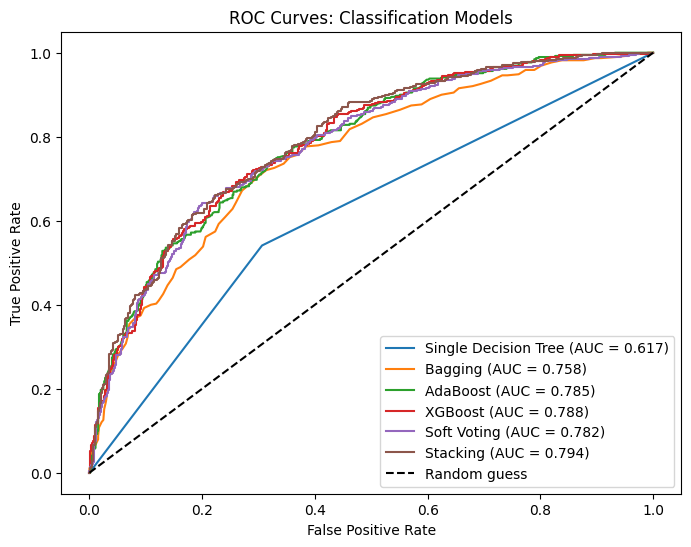

In [34]:
roc_models = [("Single Decision Tree", dt_clf), ("Bagging", bag_clf), ("AdaBoost", ada_clf),
              ("XGBoost", xgb_clf), ("Soft Voting", soft_vote), ("Stacking", stack_clf)]

plt.figure(figsize=(8, 6))
for name, model in roc_models:
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_clf_test, y_prob)
    plt.plot(fpr, tpr, label=name + " (AUC = " + str(round(roc_auc_score(y_clf_test, y_prob), 3)) + ")")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves: Classification Models")
plt.legend(loc="lower right")
plt.show()

## Evaluate Regression Models

In [35]:
reg_df = pd.DataFrame(reg_results).set_index("Model")
reg_df = reg_df.sort_values("R2", ascending=False)
reg_df.round(4)

,MAE,RMSE,R2
Model,,,
Stacking Regressor,8.0675,10.0475,0.4455
XGBoost Regressor,8.1283,10.1309,0.4362
Bagging Regressor,8.3154,10.3488,0.4117
AdaBoost Regressor,8.6081,10.5806,0.3850
Single Decision Tree (Reg),11.2243,14.1865,-0.1055


In [36]:
clf_rank = clf_df.rank(ascending=False)
clf_rank["Average Rank"] = clf_rank.mean(axis=1)

reg_rank = pd.DataFrame({
    "MAE": reg_df["MAE"].rank(ascending=True),
    "RMSE": reg_df["RMSE"].rank(ascending=True),
    "R2": reg_df["R2"].rank(ascending=False)
})
reg_rank["Average Rank"] = reg_rank.mean(axis=1)

print("Classification ranking")
print(clf_rank.sort_values("Average Rank").round(2))
print("\nRegression ranking")
print(reg_rank.sort_values("Average Rank").round(2))

best_clf = clf_df["ROC-AUC"].idxmax()
best_reg = reg_df["R2"].idxmax()
print("\nBest classification model (by ROC-AUC):", best_clf)
print("Best regression model (by R2):", best_reg)

Classification ranking
                            Accuracy  Precision  Recall   F1  ROC-AUC  \
Model                                                                   
Stacking Classifier              1.0        3.0     2.0  1.0      1.0   
XGBoost Classifier               3.0        5.0     1.0  2.0      2.0   
AdaBoost Classifier              2.0        2.0     3.0  3.0      3.0   
Voting Classifier (Soft)         4.0        4.0     6.0  4.0      4.0   
Voting Classifier (Hard)         5.0        1.0     7.0  6.0      NaN   
Bagging Classifier               6.0        6.0     5.0  5.0      5.0   
Single Decision Tree (Clf)       7.0        7.0     4.0  7.0      6.0   

                            Average Rank  
Model                                     
Stacking Classifier                 1.60  
XGBoost Classifier                  2.60  
AdaBoost Classifier                 2.60  
Voting Classifier (Soft)            4.40  
Voting Classifier (Hard)            4.75  
Bagging Classifier

In [37]:
cv_rows = []
for name, model, y, metric in [
    ("Stacking Classifier", stack_clf, y_clf_train, "roc_auc"),
    ("XGBoost Classifier", xgb_clf, y_clf_train, "roc_auc"),
    ("Voting Classifier (Soft)", soft_vote, y_clf_train, "roc_auc"),
    ("Stacking Regressor", stack_reg, y_reg_train, "r2"),
    ("XGBoost Regressor", xgb_reg, y_reg_train, "r2"),
    ("Bagging Regressor", bag_reg, y_reg_train, "r2"),
]:
    scores = cross_val_score(model, X_train, y, cv=5, scoring=metric)
    cv_rows.append({"Model": name, "Metric": metric, "CV Mean": scores.mean(), "CV Std": scores.std()})

print(pd.DataFrame(cv_rows).round(4))

                      Model   Metric  CV Mean  CV Std
0       Stacking Classifier  roc_auc   0.7838  0.0059
1        XGBoost Classifier  roc_auc   0.7739  0.0088
2  Voting Classifier (Soft)  roc_auc   0.7705  0.0062
3        Stacking Regressor       r2   0.5029  0.0060
4         XGBoost Regressor       r2   0.4895  0.0056
5         Bagging Regressor       r2   0.4628  0.0086


**Conclusion:**
- **Best classification model: Stacking Classifier** (rank 1 on accuracy, F1 and ROC-AUC; ROC-AUC about 0.794). It was chosen by ROC-AUC because it does not depend on a threshold and is not distorted by the 62/38 class imbalance.
- **Best regression model: Stacking Regressor** (rank 1 on MAE, RMSE and R2; R2 about 0.446).
- **Cross-validation confirms the order.** Stacking has the highest CV score among the ensembles on both tasks (ROC-AUC about 0.784 vs XGBoost about 0.774; R2 about 0.503 vs XGBoost about 0.490). The margin over XGBoost is small but it held in all 5 folds.
- **Ranking of ensemble types:** Stacking > XGBoost > AdaBoost / Soft Voting > Bagging > single Decision Tree on classification. Stacking > XGBoost > Bagging > AdaBoost > single Decision Tree on regression.

# Part G: Final Analysis & Reporting



## Impact of Bagging vs Boosting

| Model | Accuracy | F1 | ROC-AUC | Reg. RMSE | Reg. R2 |
|---|---|---|---|---|---|
| Single Decision Tree | 0.637 | 0.528 | 0.617 | 14.19 | -0.106 |
| Bagging | 0.701 | 0.575 | 0.758 | 10.35 | 0.412 |
| AdaBoost | 0.737 | 0.607 | 0.785 | 10.58 | 0.385 |
| XGBoost | 0.733 | 0.621 | 0.788 | 10.13 | 0.436 |

- **Bagging fixes the instability of a single tree.** A fully grown Decision Tree overfits (R2 below zero on regression). Averaging 100 trees raised ROC-AUC from 0.62 to 0.76 and R2 from -0.11 to 0.41. This is a variance reduction.
- **Boosting improved further on classification.** Both AdaBoost and XGBoost beat bagging (ROC-AUC about 0.785 to 0.788 vs 0.758), because they reduce bias as well by correcting earlier mistakes step by step.
- **On regression, boosting did not always win.** XGBoost beat bagging (R2 0.436 vs 0.412), but AdaBoost did not (0.385). Boosting is not automatically better than bagging.
- **Boosting learns fast, then flattens.** AdaBoost accuracy rose from 0.66 with one weak learner to about 0.74 by 30 to 50 learners, with almost no gain after that.

##  Comparison of Tree-Based Boosting Algorithms

| | AdaBoost | XGBoost |
|---|---|---|
| Classification ROC-AUC (test) | 0.785 | 0.788 |
| Classification F1 | 0.607 | 0.621 |
| Recall / Precision | 0.544 / 0.688 | 0.585 / 0.663 |
| Regression R2 / RMSE | 0.385 / 10.58 | 0.436 / 10.13 |
| 5-fold CV ROC-AUC | 0.770 +/- 0.008 | 0.774 +/- 0.009 |
| 5-fold CV R2 | 0.425 +/- 0.009 | 0.490 +/- 0.006 |

- **Classification:** The two are practically tied. The ROC-AUC difference (0.003) is smaller than the CV spread (about 0.008), so it is not meaningful. XGBoost finds more completers (higher recall); AdaBoost is slightly more precise.
- **Regression:** XGBoost is clearly better (RMSE 10.13 vs 10.58; CV R2 0.49 vs 0.42) and more stable across folds.
- **Why XGBoost is more robust:** it fits gradients of a loss function with L1/L2 regularization, a small learning rate (0.05) and row/column subsampling. AdaBoost only reweights samples, so it is more sensitive to noise.
- **Cost:** XGBoost has more hyperparameters; none were tuned in this project.

##  Advantages of Voting and Stacking

| Model | Accuracy | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Logistic Regression (base) | 0.745 | 0.587 | 0.634 | 0.795 |
| KNN (base) | 0.664 | 0.328 | 0.423 | 0.694 |
| SVM (base) | 0.723 | 0.559 | 0.602 | 0.762 |
| Decision Tree, depth 5 (base) | 0.703 | 0.431 | 0.521 | 0.754 |
| Voting (hard) | 0.720 | 0.436 | 0.539 | n/a |
| Voting (soft) | 0.725 | 0.508 | 0.581 | 0.782 |
| Stacking | 0.742 | 0.577 | 0.627 | 0.794 |

- **Advantage of combining different model types:** The base models (linear, distance-based, margin-based, tree) make different kinds of errors, so combining them reduces dependence on any one model's assumptions.
- **Soft vs hard voting:** Soft voting is better (recall 0.51 vs 0.44, F1 0.58 vs 0.54) because it uses confidence, and it provides probabilities for ROC-AUC.
- **Stacking vs voting:** Voting gives every model an equal vote, so the weak KNN (accuracy 0.66) pulled the soft vote below Logistic Regression alone. Stacking learns the weights, ignores the weak model, and reached the level of the best base model (ROC-AUC 0.794). On regression, stacking (R2 0.446) was about equal to Ridge (0.444).
- **Limits:** Voting and stacking need every base model at prediction time. Stacking is also slower to train (about 10 seconds vs under 1 second for LR). Here, neither beat Logistic Regression / Ridge by a meaningful margin.

## Final Model Recommendation for Deployment

| Task | Best ensemble | Key results | 5-fold CV |
|---|---|---|---|
| Course completion (classification) | **Stacking Classifier** | Accuracy 0.742, F1 0.627, ROC-AUC 0.794 | ROC-AUC 0.784  |
| Final score (regression) | **Stacking Regressor** | MAE 8.07, RMSE 10.05, R2 0.446 | R2 0.503  |


- They were the best of all ensemble techniques on every primary metric, and they beat XGBoost in all 5 CV folds, although by a small margin (about 0.01 ROC-AUC, 0.014 R2).
- The stacking meta-learner weights its base models, so it tends to stay close to the best base model if the data changes. Single models are less protected against that.
- Cost is acceptable: training takes seconds and prediction is fast.


##  Business Interpretation
- **Completion prediction** (ROC-AUC about 0.79) is good for ranking students by risk of not finishing, so support can be targeted. At the default threshold the model finds about 58% of students who complete, and about 69% of its "will complete" predictions are correct. It should be used as an early-warning signal, not as a final decision about any student.
- **Score prediction** is off by about 8 points on average (MAE 8.07 on a 0 to 100 scale) and explains about 45% of the variation in final scores. It is suitable for rough forecasting, not for grading or high-stakes decisions.
- **Overall:** Ensembles clearly improved on unstable single models such as the Decision Tree, which was the problem the manager described. Beyond that, extra model complexity gave very little improvement on this dataset.